In [9]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
K_0=1
N = K_0*np.power(E, -p)
B = 1
E_ph = np.geomspace(1e-30, 1e-3, 150)

########################################################################################################

print(PowerFunction(1e-16,E[0],B),q(1e-16,B,N,E)/(4*np.pi),k_SSA(1e-16,E,N,B))

/tmp/ipykernel_10907/1289138028.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)
/tmp/ipykernel_10907/835747678.py:15: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  der_factor = derivative(logne, loge) - 2 #For a power law, the derivative should be (-p)


0.0 89547579223.88155 1.0651380367282474e-10


In [1]:
import numpy as np
from astropy.constants import c, e, h, m_e
import matplotlib.pyplot as plt

c = c.cgs.value
e = e.gauss.value
h = h.cgs.value
m_e = m_e.cgs.value


/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Defino la funcion de potencia

In [2]:
def PowerFunction(E_ph, E, B, pitch_angle=np.pi/2):
    """
    Compute the emitted power as a function of energy, photon energy, magnetic field, and pitch angle.
    
    Parameters:
        E_ph (float or np.ndarray): Photon energy.
        E (float or np.ndarray): Energy of the particle.
        B (float): Magnetic field strength.
        pitch_angle (float): Pitch angle (default is pi/2).
    
    Returns:
        np.ndarray: Power emitted at the given photon energy.
    """
    # Define constants
    K = np.sqrt(3) * e**3 / (h * m_e * c**2)   #En el codigo fuente de agnpy es distinto
    Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle))/ (m_e**3 * c**5) *np.power(E,2)
    
    #constants acording to agnpy
    #K = np.sqrt(3) * e**3 / h
    #Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle))/ (m_e**2 * c**3) *np.power(E,2)


    x = E_ph / Ec
        # Define an array for the Bessel integral approximation
    R = np.zeros_like(x)
    
    #(Aharonian+2010)
    #R=2.15*np.power(x, 1./3.)*np.power(1.+3.06*x,1./6.)*(1.+0.884*np.power(x,2./3.)+0.471*np.power(x,4./3.))/(1+1.64*np.power(x,2./3.)+0.974*np.power(x,4./3.))*np.exp(-x)
    
    #Function G(x), (Aharonian+2010)
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    R=term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)

    # #(Finke+2008)
    
    # # Define coefficient sets for different ranges
    # coef_1 = (-0.35775237, -0.83695385, -1.1449608, -0.68137283, -0.22754737, -0.031967334)
    # coef_2 = (-0.35842494, -0.79652041, -1.6113032, 0.26055213, -1.6979017, 0.032955035)
    
    # # Apply the first set of coefficients (1e-2 < x < 1)
    # mask_1 = (x > 1e-2) & (x < 1)
    # R[mask_1] = np.exp(
    #     sum(c * x[mask_1] ** i for i, c in enumerate(coef_1))
    # )
    
    # # Apply the second set of coefficients (1 <= x < 10)
    # mask_2 = (x >= 1) & (x < 10)
    # R[mask_2] = np.exp(
    #     sum(c * x[mask_2] ** i for i, c in enumerate(coef_2))
    # )
    
    # #(Apunte de IAR)
    # R = np.power(x, 1./3.) * np.exp(-x)

    # # Compute the emitted power
    P = K * B  * R* np.sin(pitch_angle)
    return P # [erg s^-1 erg^-1]


## Absorcion

### Coef de absorcion de agnpy

In [3]:
from agnpy.utils.math import axes_reshaper
from agnpy.utils.conversion import lambda_c_e
import astropy.units as u

def absorcion_agnpy(epsilon,B_cgs,n_e,k, p, gamma_min, gamma_max,gamma,integrator=np.trapz):
    def evaluate_SSA_integrand(gamma, k, p, gamma_min, gamma_max):
        r"""Analytical integrand for the synchrotron self-absorption:
        :math:`\gamma'^2 \frac{d}{d \gamma'} \left(\frac{n(\gamma)}{\gamma'^2}\right)`."""
        return k * np.where(
            (gamma_min <= gamma) * (gamma <= gamma_max),
            -(p + 2) * np.power(gamma, -p - 1),
            0,
        )
    _gamma, _epsilon = axes_reshaper(gamma, epsilon)
    SSA_integrand = evaluate_SSA_integrand(_gamma, k, p, gamma_min, gamma_max)
    integrand = SSA_integrand * single_particle_synch_power(B_cgs, _epsilon, _gamma)
    integral = integrator(integrand, gamma, axis=0)
    prefactor_k_epsilon = (
        -1 / (8 * np.pi * m_e * np.power(epsilon, 2)) * np.power(lambda_c_e / c, 3)
    )
    k_epsilon = (prefactor_k_epsilon * integral)
    return k_epsilon

######################################################################################################

Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
K_0=1e22
N = K_0*np.power(E, -p)
B = 1
E_ph = np.geomspace(1e-30, 1e-3, 150)

gamma=E/(m_e*c**2)
epsilon=E_ph/(m_e*c**2)
cte_abs=absorcion_agnpy(epsilon,B,N,K_0,p,Emin/(m_e*c**2),Emax/(m_e*c**2),gamma=gamma)


NameError: name 'single_particle_synch_power' is not defined

### Coef de absorcion

In [3]:
from scipy.interpolate import interp1d
from scipy.misc import derivative
import scipy.integrate as integrate
def k_SSA(E_ph, eVec, neVec, bField):


    #we create a function that relates N with E, instead of 2 column table
    logne = interp1d(np.log(eVec), np.log(neVec), bounds_error=False, fill_value="extrapolate")
    def ne_e2(E_e):
        return np.exp(logne(np.log(E_e)))/(E_e*E_e)
    
    #We define the integrand, the function that we will integrate
    def integrand(loge, E_ph, bField):
        E_e = np.exp(loge)
        der_factor = derivative(logne, loge) - 2 #For a power law, the derivative should be (-p)
        if der_factor < 0. and der_factor > -10.:
            return E_e * PowerFunction(E_ph, E_e, bField) * E_e * ne_e2(E_e) * der_factor
        else:
            return 0.
    integral = integrate.quad(integrand, np.log(eVec[0]*1.1), np.log(eVec[-1]/1.1), args=(E_ph, bField))[0]
    return - h**3*c**2/ (8.*np.pi*E_ph*E_ph) * integral

In [17]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
K_0=1
N = K_0*np.power(E, -p)
B = 1807.6245791248984
E_ph = np.geomspace(1e-30, 1e-3, 150)

P = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    P[i] = PowerFunction(e_, E, B)


In [7]:
k_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    k_vec[i] = k_SSA(e_, E, N, B)

/tmp/ipykernel_7639/835747678.py:15: DeprecationWarning: scipy.misc.derivative is deprecated in SciPy v1.10.0; and will be completely removed in SciPy v1.12.0. You may consider using findiff: https://github.com/maroba/findiff or numdifftools: https://github.com/pbrod/numdifftools
  der_factor = derivative(logne, loge) - 2 #For a power law, the derivative should be (-p)


### Coef de absorcion de IAR

In [59]:
from scipy.special import gamma  # gamma es la función gamma

def absorption_coef(E_ph, K_0, p, B):
    '''


    Parámetros:
        E_ph: Photon energy
        K_0: Normalization constant of the N(E)
        p: Power law index
        B: Magnetic field power
    '''

    #Change from energy to frequency

    nu=E_ph/h

    gamma_factors = (gamma((3 * p + 2) / 12) *gamma((3 * p + 22) / 12) *gamma((p + 6) / 4) /gamma((p + 8) / 4))

    A = np.sqrt(3) * e**3 / (8 * np.pi * m_e) * (3 * e / (4 * np.pi * m_e**3 * c**5))**(p / 2)  * np.sqrt(np.pi/2) *c * K_0* B**((p + 2) / 2)

    A*=gamma_factors

    return A * nu**(-(p + 4) / 2)



In [60]:
alpha = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    alpha[i] = absorption_coef(e_, K_0, p, B)

### Grafico

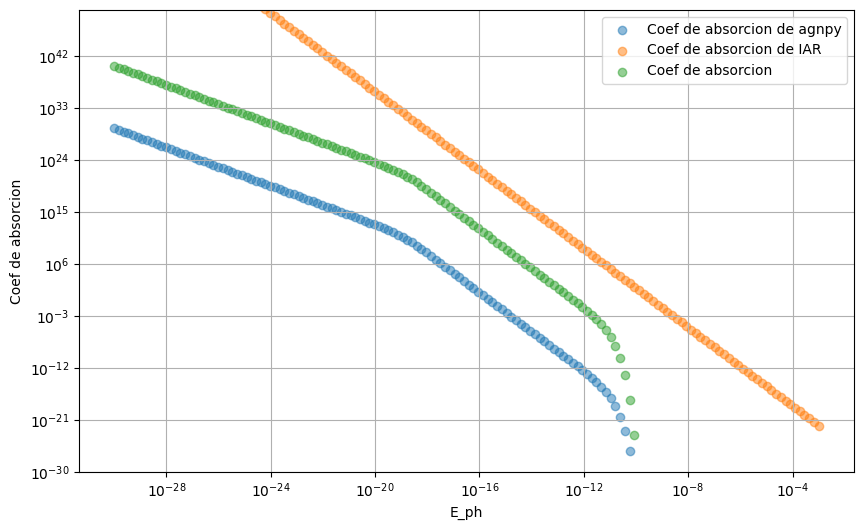

In [61]:
# Plotting
plt.figure(figsize=(10, 6))

# Plot single-particle synchrotron power
plt.scatter(E_ph, cte_abs, label="Coef de absorcion de agnpy", marker='o', alpha=0.5)
plt.scatter(E_ph, alpha, label="Coef de absorcion de IAR", marker='o', alpha=0.5)
# Plot power function
plt.scatter(E_ph, k_vec, label="Coef de absorcion", marker='o', alpha=0.5)

# Labels and title
plt.xlabel("E_ph")
plt.ylabel("Coef de absorcion")
plt.title("")
plt.legend(bbox_to_anchor=[1, 1])
plt.grid()
plt.ylim(1e-30,1e50)
plt.xscale('log')
plt.yscale('log')
# Show the plot
plt.show()

In [19]:
P = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    P[i] = PowerFunction(e_, E, B)


### Comparacion de potencias (agnpy y PowerFunction)
# --------------------------------------------------------------------------------------------------

In [4]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
K_0=1e22
N = K_0*np.power(E, -p)
B = 1
E_ph = np.geomspace(1e-30, 1e-3, 150)

P = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    P[i] = PowerFunction(e_, E, B)

#print(E)
#print(PowerFunction(1e-20,E,B))

In [54]:
#Lo siguiente es un extracto del codigo de agnpy
def R(x):
    """Eq. 7.45 in [Dermer2009]_, angle-averaged integrand of the radiated power, the
    approximation of this function, given in Eq. D7 of [Aharonian2010]_, is used.
    """
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    return term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)


def calc_x(B_cgs, epsilon, gamma, mass=m_e):
    """ratio of the frequency to the critical synchrotron frequency from
    Eq. 7.34 in [DermerMenon2009]_, argument of R(x),
    note B has to be in cgs Gauss units"""
    
    x = (
        4
        * np.pi
        * epsilon
        * np.power(mass, 2)
        * np.power(c, 3)
        / (3 * e * B_cgs * h * np.power(gamma, 2))
    )
    return x

def single_particle_synch_power(B_cgs, epsilon, gamma, mass=m_e):
    """angle-averaged synchrotron power for a single particle of mass m_e,
    to be folded with the electron distribution
    """
    x = calc_x(B_cgs, epsilon, gamma, mass)
    prefactor = np.sqrt(3) * np.power(e, 3) * B_cgs / h
    
    return prefactor * R(x)


#Como dato de entrada paso los gamma asociado a la energia de e- del array que use antes
gamma=E/(m_e*c**2)
epsilon=E_ph/(m_e*c**2)
#spsp es single particle synchrotron power
spsp = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(epsilon):
    spsp[i] = single_particle_synch_power(B, e_, gamma, m_e )


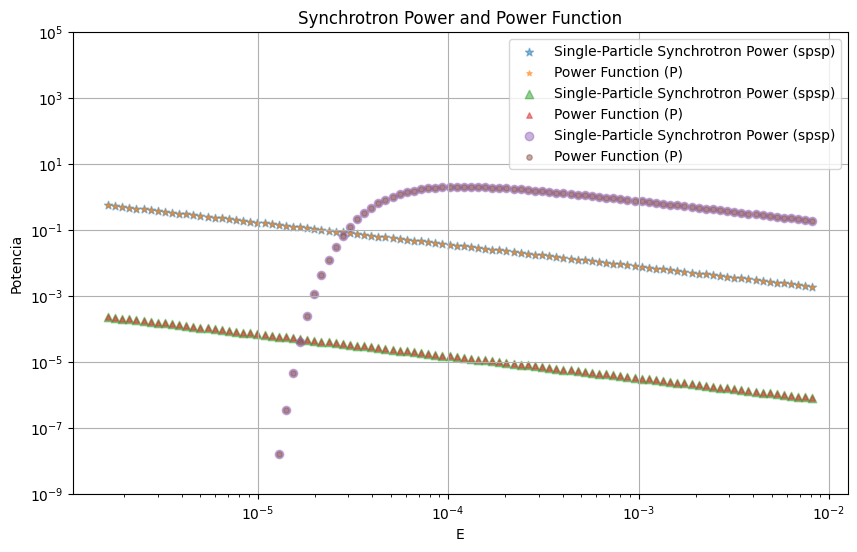

In [21]:
#Basic plotting code

# Plotting
plt.figure(figsize=(10, 6))

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[56], label="Single-Particle Synchrotron Power (spsp)", marker='*', alpha=0.5)
# Plot power function
plt.scatter(E, P[56]*m_e*c**2, label="Power Function (P)", s=15, marker='*', alpha=0.5)

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[0], label="Single-Particle Synchrotron Power (spsp)", marker='^', alpha=0.5)
# Plot power function
plt.scatter(E, P[0]*m_e*c**2, label="Power Function (P)", s=15, marker='^', alpha=0.5)

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[89], label="Single-Particle Synchrotron Power (spsp)", marker='o', alpha=0.5)
# Plot power function
plt.scatter(E, P[89]*m_e*c**2, label="Power Function (P)", s=15, marker='o', alpha=0.5)

# Labels and title
plt.xlabel("E")
plt.ylabel("Potencia")
plt.title("Synchrotron Power and Power Function")
plt.legend(bbox_to_anchor=[1, 1])
plt.grid()
plt.ylim(1e-9,1e5)
plt.xscale('log')
plt.yscale('log')
# Show the plot
plt.show()

# -------------------------------------------------------------------------------------------------------

In [27]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
N = np.power(E, -p)
B = 1.0
E_ph = np.geomspace(1e-30, 1e-3, 150)


## Emisividad

### Defino la emisividad

In [4]:
def q(E_ph, B, N, E):
    integ = PowerFunction(E_ph, E, B)*N
    return np.trapz(integ, E)
    # int(P(E_ph, E, B) N(E) dE)

In [10]:
q_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    q_vec[i] = q(e_, B, N, E)
# Emin = 1.6021760000000001E-006#2*m_e*c**2
# Emax = 8010.8799999999055#1e4*m_e*c**2
# E = np.geomspace(Emin, Emax, 150)
# p = 2.8
# K_0=1e22
# N = np.array([2.3548693141398899E+050,  1.6273448126443852E+050,  9.5286349925038991E+049,  5.6558091862463591E+049,  3.3882796155001039E+049,  2.0422587658678569E+049,  1.2361638027729923E+049,  7.5043264107692270E+048,  4.5644953093642940E+048,  2.7800499886832124E+048,  1.6947130791329377E+048,  1.0336679276457512E+048,  6.3068912913140308E+047,  3.8488548360789349E+047,  2.3490022087060681E+047,  1.4336410990316473E+047,  8.7494689305605247E+046,  5.3394202577677162E+046,  3.2581286417623476E+046,  1.9879227652118258E+046,  1.2127886788237427E+046,  7.3981278163567891E+045,  4.5124218093285546E+045,  2.7519952228496560E+045,  1.6781596113670964E+045,  1.0232137940578456E+045,  6.2379888201534990E+044,  3.8024538980454549E+044,  2.3175130404420426E+044,  1.4122575514768557E+044,  8.6046360269192232E+043,  5.2417029830070235E+043,  3.1924485696799924E+043,  1.9439124828796967E+043,  1.1833706168824501E+043,  7.2017862319720517E+042,  4.3814713110534755E+042,  2.6646724485716309E+042,  1.6198953556806006E+042,  9.8430165086911281E+041,  5.9778174962794023E+041,  3.6282100556328423E+041,  2.2006386428666459E+041,  1.3337481910457128E+041,  8.0762846593118939E+040,  4.8856585719671549E+040,  2.9522303937381749E+040,  1.7816259267543693E+040,  1.0736538103704249E+040,  6.4596213643900235E+039,  3.8791968830060354E+039,  2.3247897713218373E+039,  1.3899680227845351E+039,  8.2883395995430289E+038,  4.9277344631609626E+038,  2.9198158288969979E+038,  1.7234920502793824E+038,  1.0130377964421170E+038,  5.9255140143376319E+037,  3.4472142160271358E+037,  1.9933418667335788E+037,  1.1445995843777073E+037,  6.5217133785163472E+036,  3.6838581996082634E+036,  2.0599663306929643E+036,  1.1392041711187108E+036,  6.2215834053165657E+035,  3.3487462415142021E+035,  1.7737928414393353E+035,  9.2254779873107610E+034,  4.6979721606370815E+034,  2.3370194825122839E+034,  1.1316791578914497E+034,  5.3130140722072941E+033,  2.4094830071577252E+033,  1.0497079546769597E+033,  4.3675889845053327E+032,  1.7254438930340907E+032,  6.4152242226636363E+031,  2.2257237569933527E+031,  7.1382389835051912E+030,  2.0864800769749843E+030,  5.4889164621163012E+029,  1.2800170083874015E+029,  2.5862700146992136E+028,  4.4443273368064636E+027,  6.3366350271039920E+026,  7.2299388677239823E+025,  6.4181053085003264E+024,  4.2542826841330258E+023,  1.9945842202273022E+022,  6.3184755100214821E+020,  1.2647493422247944E+019,  1.4748055413508211E+017,  930148393183823.62,       2844751848591.7485,       3735545645.6975932,       1867297.2549953037,       297.49796091226790,       1.2596744687367132E-002,  1.1671233838226426E-007,  1.7743746774618947E-013,  3.3815814194975024E-020,  5.9132983302480297E-028,  5.9660424485078079E-037,  2.3381147109955003E-047,  2.1604126708537550E-059,  2.2310624759263251E-073,  1.4423176784470295E-089,  2.5587221923718244E-108,  4.0334054102649764E-130,  2.2488174595763738E-155,  1.1596816072617616E-184,  1.0281862012802660E-218,  3.5562357202346215E-258,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042,  1.7944162899688408E-042])
# B = 1807.6245791248984
# E_ph = np.geomspace(1e-30, 1e-3, 150)


/tmp/ipykernel_7639/1289138028.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)


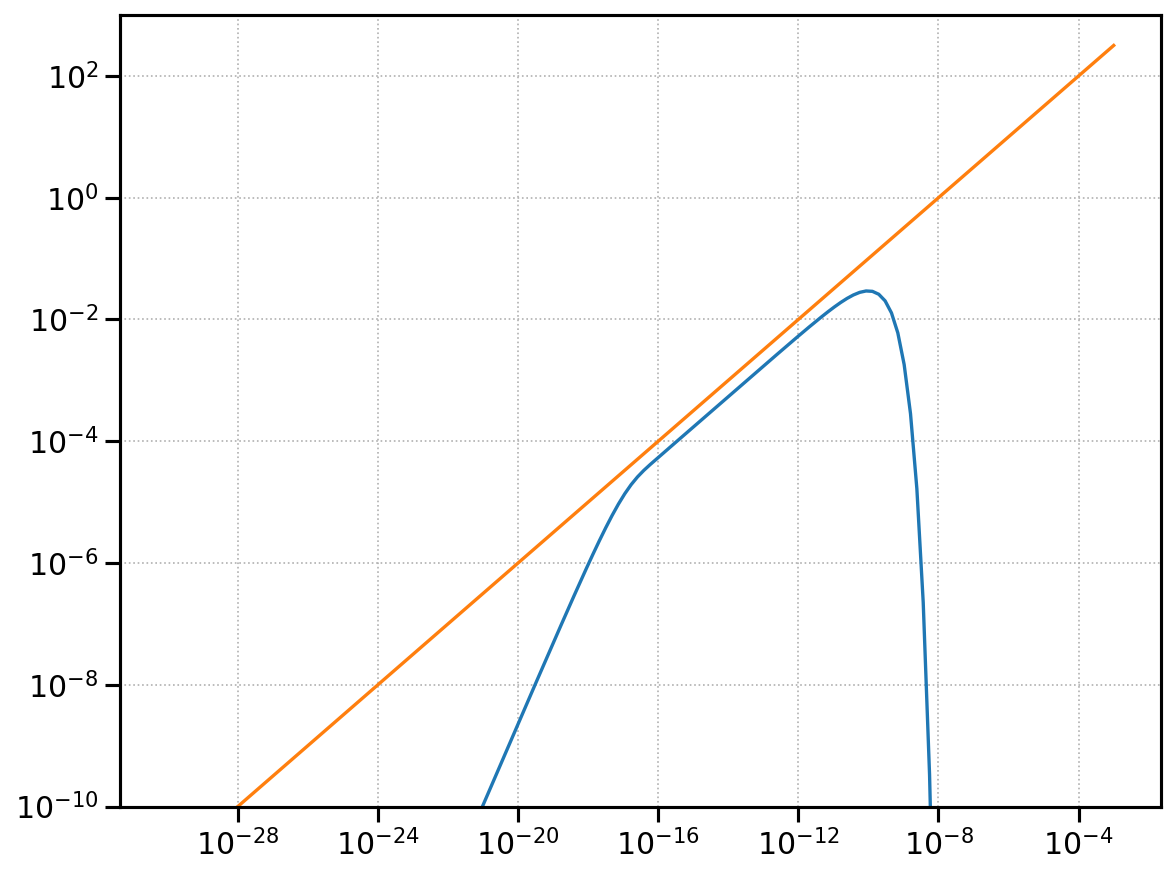

In [ ]:
plt.ylim(1e-10, 1e3)
plt.loglog(E_ph, E_ph*q_vec)
plt.loglog(E_ph, 10000*np.power(E_ph, 0.5))

In [37]:
# def calcular_emisividad(P, N, E, E_ph, B):
#     """
#     Calcula una integral definida usando el método del simpson.
    
#     Parámetros:
#     - P: Potencia emitida por particula
#     - N: Numero de particulas para una dada energia
#     - E: array de energias
#     - E_ph: Energia del foton emitido
#     - B: Magnitud del campo magnetico
#     """
    
#     if len(E) % 2 != 0:
#         raise ValueError("El número de subintervalos debe ser par para la regla de Simpson.")
#     # Definimos el producto que va en la integral
#     y = P(E_ph,E,B)[0][:][0]*N
    
#     # Aplicar la regla de Simpson
#     h = (np.max(E) - np.min(E)) / (len(E))
#     integral = h / 3 * (y[0] + 4 * np.sum(y[1:len(E):2]) + 2 * np.sum(y[2:len(E)-1:2]) + y[-1])
#     return integral

# E = np.linspace(1e-3, 1e6, 3000)  # Energia de las particulas
# E_ph = np.linspace(1e-3, 1e1, 50)  # Energia de los fotones
# B = np.linspace(1e6, 6e6, 6)  # magnitud del campo magnetico

# print(B)

# N=1e5*E**-2
# j = np.empty((len(E_ph), len(B))) 
# for i, energy in enumerate(E_ph):
#     for k, magnitude in enumerate(B):
#         j[i,k]+=1/(4*np.pi)*calcular_emisividad(PowerFunctionSYNC,N,E,energy,magnitude)

# print(j.shape)



In [45]:
# import pandas as pd

# df= pd.DataFrame(j, columns=B, index=E_ph)

# df

In [46]:
# import matplotlib.pyplot as plt

# #df.drop(columns=[5000000.0], inplace=True)
# df.plot(kind='line', marker='o')
# plt.title('Grafico de emisividad a distintas frecuencias/energias en funcion del campo magnetico a altura z')
# plt.xlabel('Energia')
# plt.ylabel('Emisividad')
# plt.show

### Comparo emisividad (agnpy y funcion q)

In [47]:
# pip install agnpy

In [48]:
Emin = 1e2*m_e*c**2
Emax = 1e7*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
N = 3e38*np.power(E, -p)
B = 1
E_ph = h*np.logspace(8,23,50)#np.geomspace(1e-30, 1e-3, 150)

q_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    q_vec[i] = q(e_, B, N, E)

/tmp/ipykernel_5022/2814496126.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)


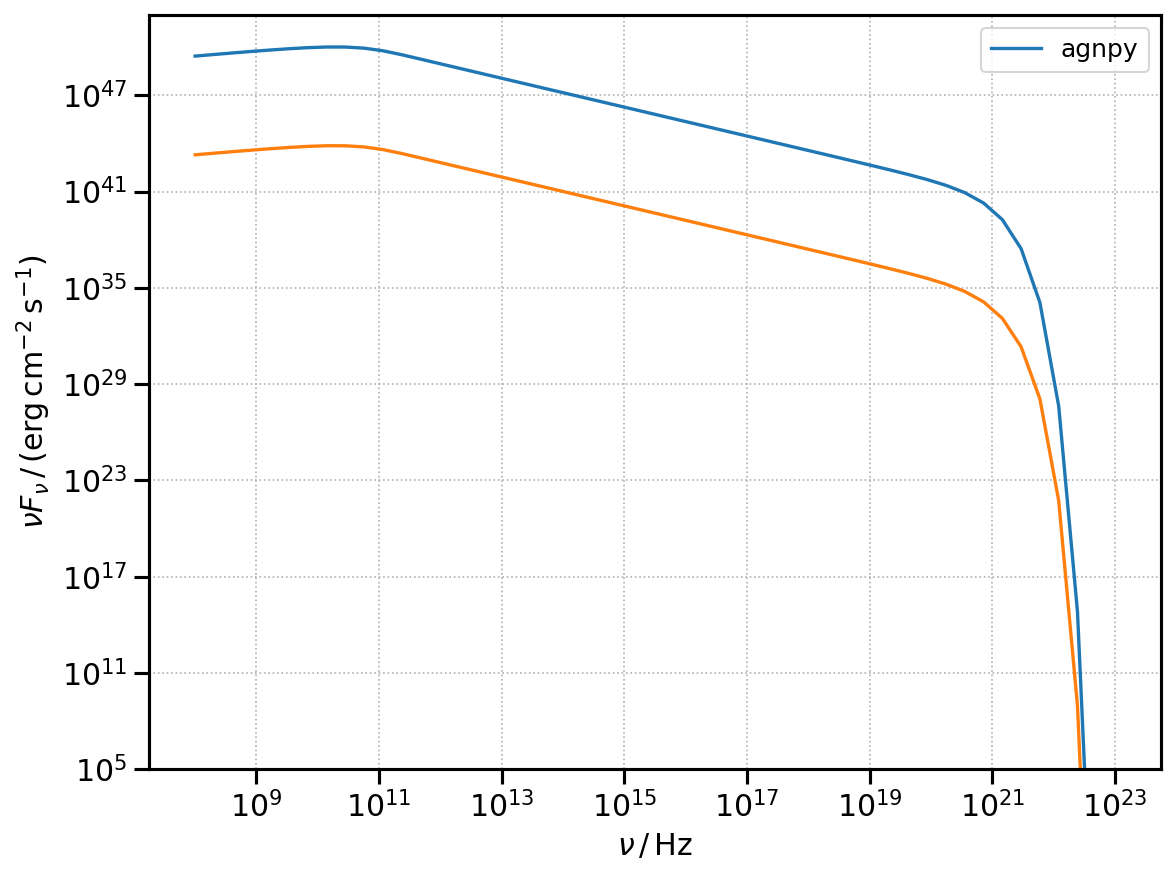

In [49]:
import numpy as np
import astropy.units as u
from astropy.constants import m_e as m_e2
from astropy.coordinates import Distance
from agnpy.spectra import PowerLaw
from agnpy.emission_regions import Blob
from agnpy.synchrotron import Synchrotron
from agnpy.utils.plot import load_mpl_rc, plot_sed
import matplotlib.pyplot as plt
from agnpy.utils.conversion import nu_to_epsilon_prime


# set the quantities defining the blob
R_b = 1e16 * u.cm
V_b = 4 / 3 * np.pi * R_b ** 3
z = Distance(1e21, unit=u.cm).z ##Menos de esta cantidad y falla
delta_D = 1
Gamma = 1
B = 1 * u.G

# electron distribution
W_e = 1e48 * u.erg#1e75 * u.erg # total energy in electrons

n_e = PowerLaw.from_total_energy(
    W_e,
    V_b,
    p=2.8,
    gamma_min=1e2,
    gamma_max=1e7,
    mass=m_e2,
)

# define the emission region and the radiative process
blob = Blob(R_b, z, delta_D, Gamma, B, n_e=n_e)
synch = Synchrotron(blob)

# compute the SED over an array of frequencies
nu = np.logspace(8, 23) * u.Hz


#Provando cosas

epsilon = nu_to_epsilon_prime(nu, z, delta_D, m = m_e2)
prefactor = np.power(delta_D, 4) / (4 * np.pi * np.power(blob.d_L, 2))
emisividad = synch.sed_flux(nu)/(epsilon*prefactor) #Multiplico por epsilon y prefactor para recuperar emisividad

# load matplotlib configuration for agnpy
load_mpl_rc() #Esta precargado, asi que cambiar los nombres de los ejes es mas trabajo. Recordar que es 


plot_sed(nu, emisividad, label="agnpy" )
plt.ylim(1e5,1e52)
plt.loglog(E_ph/h, q_vec, label='local')
plt.show()

## Notas relevantes

#### Asi se construye la sed Synchrotron
```
#conversions
        epsilon = nu_to_epsilon_prime(nu, z, delta_D, m = m_e)
        B_cgs = B_to_cgs(B)
        # reshape for multidimensional integration
        _gamma, _epsilon = axes_reshaper(gamma, epsilon)
        V_b = 4 / 3 * np.pi * np.power(R_b, 3)
        N_e = V_b * n_e.evaluate(_gamma, *args)
        # fold the electron distribution with the synchrotron power
        integrand = N_e * single_particle_synch_power(B_cgs, _epsilon, _gamma)
        emissivity = integrator(integrand, gamma, axis=0).reshape(epsilon.shape)
        prefactor = np.power(delta_D, 4) / (4 * np.pi * np.power(d_L, 2))
        sed = (prefactor * epsilon * emissivity).to("erg cm-2 s-1")
```

In [244]:
#Funcion aproximacion de la funcion G(x) del apendice D [Aharonian2010]
def R(x):
    """Eq. 7.45 in [Dermer2009]_, angle-averaged integrand of the radiated power, the
    approximation of this function, given in Eq. D7 of [Aharonian2010]_, is used.
    """
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    return term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)